Q1
Importing necessary libraries for data analysis and visualization

In [1]:
import pandas as pd
import numpy as np
import sqlite3
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

#Project paths
PROJECT_DIR = Path.cwd()
DATA_DIR = PROJECT_DIR / "data"

print("Libraries imported successfully.")
print("Project directory:", PROJECT_DIR)
print("Data directory:", DATA_DIR)

Libraries imported successfully.
Project directory: c:\Users\prapul.k.midde\Downloads\DC_Vehicle_Management
Data directory: c:\Users\prapul.k.midde\Downloads\DC_Vehicle_Management\data


Loading vehicle, maintenance and mechanic datasets using pandas

In [3]:
vehicle_df = pd.read_csv(DATA_DIR / "vehicle(in).csv")
maintenance_df = pd.read_csv(DATA_DIR / "maintenance(in).csv")
mechanic_df = pd.read_csv(DATA_DIR / "mechanic(in).csv")

print("=" * 50)
print("VEHICLE DATASET")
print("=" * 50)
display(vehicle_df.head())

print("\n" + "=" * 50)
print("MAINTENANCE DATASET")
print("=" * 50)
display(maintenance_df.head())

print("\n" + "=" * 50)
print("MECHANIC DATASET")
print("=" * 50)
display(mechanic_df.head())

print("\n DATASET SHAPES" )
print("Vehicles:", vehicle_df.shape)
print("Maintenance:", maintenance_df.shape)
print("Mechanics:", mechanic_df.shape)

VEHICLE DATASET


,ID,Make,Model,Color,Mileage,Year
0,1001,Kia,Seltos,White,77097,2018
1,1002,Honda,Civic,Red,31868,2025
2,1003,Kia,Carens,White,115604,2015
3,1004,Toyota,Corolla,Black,65990,2023
4,1005,Tata,Nexon,Grey,57124,2025



MAINTENANCE DATASET


,MaintainanceID,VehicleID,Cost,MechanicID,StartTime,EstimatedDeliveryDate,ActualDeliveryDate,CustomerRating
0,5001,1029,2774,203,12/17/2025 9:00,12/19/2025 11:00,12/19/2025 11:00,5.0
1,5002,1017,7782,201,11/4/2025 14:00,11/7/2025 18:00,11/7/2025 21:00,4.0
2,5003,1020,7889,202,5/18/2026 9:00,5/19/2026 11:00,5/22/2026 14:00,4.0
3,5004,1003,14442,207,3/14/2025 13:00,3/19/2025 13:00,3/18/2025 19:00,3.0
4,5005,1007,9064,204,11/18/2025 12:00,11/22/2025 16:00,11/22/2025 22:00,3.0



MECHANIC DATASET


,MechanicID,MechanicName
0,201,Arun Kumar
1,202,Priya Sharma
2,203,Ravi Teja
3,204,Sneha Reddy
4,205,Imran Khan



 DATASET SHAPES
Vehicles: (30, 6)
Maintenance: (72, 8)
Mechanics: (8, 2)


Question 2
Analyzed dataset shape, data types, records, year range, etc.;

In [6]:
datasets = {
    "Vehicle": vehicle_df,
    "Maintenance": maintenance_df,
    "Mechanic": mechanic_df
}

for name, df in datasets.items():
    print("\n" + "=" * 50)
    print(name.upper(), "DATASET")
    print("=" * 50)

    print("Shape:", df.shape)
    print("\n Data Types:")
    print(df.dtypes)

print("\n" + "=" * 50)
print("DATASET INSIGHTS")
print("=" * 50)

print("Number of Vehicles:", len(vehicle_df))
print("Number of Maintenance Records:", len(maintenance_df))
print("Number of Mechanics:", len(mechanic_df))

print("\nUnique Vehicle Makes:")
print(vehicle_df["Make"].dropna().unique())

print("\nNumber of Unique Vehicle Makes:")

print("\nManufacturing Year Range:")
print("Minimum Year:", vehicle_df["Year"].min())
print("Maximum Year:", vehicle_df["Year"].max())


VEHICLE DATASET
Shape: (30, 6)

 Data Types:
ID         int64
Make         str
Model        str
Color        str
Mileage    int64
Year       int64
dtype: object

MAINTENANCE DATASET
Shape: (72, 8)

 Data Types:
MaintainanceID             int64
VehicleID                  int64
Cost                       int64
MechanicID                 int64
StartTime                    str
EstimatedDeliveryDate        str
ActualDeliveryDate           str
CustomerRating           float64
dtype: object

MECHANIC DATASET
Shape: (8, 2)

 Data Types:
MechanicID      int64
MechanicName      str
dtype: object

DATASET INSIGHTS
Number of Vehicles: 30
Number of Maintenance Records: 72
Number of Mechanics: 8

Unique Vehicle Makes:
<StringArray>
['Kia', 'Honda', 'Toyota', 'Tata', 'Hyundai', 'Maruti Suzuki']
Length: 6, dtype: str

Number of Unique Vehicle Makes:

Manufacturing Year Range:
Minimum Year: 2015
Maximum Year: 2025


Q 2(b)
Replaced Missing numerical Values with the mean and categorical Values

In [12]:
for df in [vehicle_df, maintenance_df, mechanic_df]:
    print("\nBefore:\n", df.isnull().sum())

    for col in df.select_dtypes(include="number"):
        df[col] = df[col].fillna(df[col].mean())

    for col in df.select_dtypes(include="object"):
        if col not in ["StartTime", "EstimatedDeliveryDate", "ActualDeliveryDate"]:
            df[col].fillna("Not Found")

    print("\nAfter: \n", df.isnull().sum)
                       


Before:
 ID         0
Make       0
Model      0
Color      0
Mileage    0
Year       0
dtype: int64

After: 
 <bound method DataFrame.sum of        ID   Make  Model  Color  Mileage   Year
0   False  False  False  False    False  False
1   False  False  False  False    False  False
2   False  False  False  False    False  False
3   False  False  False  False    False  False
4   False  False  False  False    False  False
5   False  False  False  False    False  False
6   False  False  False  False    False  False
7   False  False  False  False    False  False
8   False  False  False  False    False  False
9   False  False  False  False    False  False
10  False  False  False  False    False  False
11  False  False  False  False    False  False
12  False  False  False  False    False  False
13  False  False  False  False    False  False
14  False  False  False  False    False  False
15  False  False  False  False    False  False
16  False  False  False  False    False  False
17  False  F

C:\Users\prapul.k.midde\AppData\Local\Temp\ipykernel_12692\3995863183.py:7: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  for col in df.select_dtypes(include="object"):
C:\Users\prapul.k.midde\AppData\Local\Temp\ipykernel_12692\3995863183.py:7: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/use

Q 2(C)
Identified and removed duplicates

In [13]:
for name, df in datasets.items():
    print(name, "Duplicates Before:", df.duplicated().sum())

    vehicle_df = vehicle_df.drop_duplicates()
    maintenance_df = maintenance_df.drop_duplicates()
    mechanic_df = mechanic_df.drop_duplicates()

for name, df in {
    "Vehicle": vehicle_df,
    "Maintenance": maintenance_df,
    "Mechanic": mechanic_df
}.items():
    print(name, "Duplicates After:", df.duplicated().sum())

Vehicle Duplicates Before: 0
Maintenance Duplicates Before: 0
Mechanic Duplicates Before: 0
Vehicle Duplicates After: 0
Maintenance Duplicates After: 0
Mechanic Duplicates After: 0


Q 2d
Calculated mean, min,max for numericacl columns


In [14]:
display(vehicle_df[["Mileage", "Year"]].describe())
display(maintenance_df[["Cost", "CustomerRating"]].describe())

,Mileage,Year
count,30.000000,30.000000
mean,64453.366667,2021.433333
std,32961.939580,3.223655
min,13414.000000,2015.000000
25%,37985.000000,2020.000000
50%,62678.500000,2022.000000
75%,76569.250000,2024.000000
max,135870.000000,2025.000000


,Cost,CustomerRating
count,72.000000,72.000000
mean,7235.138889,4.128571
std,5425.671977,1.005918
min,1201.000000,1.000000
25%,3163.000000,4.000000
50%,5187.500000,4.000000
75%,8839.750000,5.000000
max,24284.000000,5.000000


Q 2(e) SetID, MaintenanceID and MechanicID as indexes for respective dataframes

In [17]:
for df, col in [
    (vehicle_df, "ID"),
    (maintenance_df, "MaintenaceID"),
    (mechanic_df, "MechanicID")
]:
    if col in df.columns:
        df.set_index(col, inplace=True)
    else:
        print(col, "not found. Current index:", df.index.name)


display(vehicle_df.head())
display(maintenance_df.head())
display(mechanic_df.head())

ID not found. Current index: ID
MaintenaceID not found. Current index: None


C:\Users\prapul.k.midde\AppData\Local\Temp\ipykernel_12692\2466767964.py:7: Pandas4Warning: The inplace keyword in DataFrame.set_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.set_index(col, inplace=True)


,Make,Model,Color,Mileage,Year
ID,,,,,
1001,Kia,Seltos,White,77097,2018
1002,Honda,Civic,Red,31868,2025
1003,Kia,Carens,White,115604,2015
1004,Toyota,Corolla,Black,65990,2023
1005,Tata,Nexon,Grey,57124,2025


,MaintainanceID,VehicleID,Cost,MechanicID,StartTime,EstimatedDeliveryDate,ActualDeliveryDate,CustomerRating
0,5001,1029,2774,203,12/17/2025 9:00,12/19/2025 11:00,12/19/2025 11:00,5.0
1,5002,1017,7782,201,11/4/2025 14:00,11/7/2025 18:00,11/7/2025 21:00,4.0
2,5003,1020,7889,202,5/18/2026 9:00,5/19/2026 11:00,5/22/2026 14:00,4.0
3,5004,1003,14442,207,3/14/2025 13:00,3/19/2025 13:00,3/18/2025 19:00,3.0
4,5005,1007,9064,204,11/18/2025 12:00,11/22/2025 16:00,11/22/2025 22:00,3.0


,MechanicName
MechanicID,
201,Arun Kumar
202,Priya Sharma
203,Ravi Teja
204,Sneha Reddy
205,Imran Khan


Q3 
Joined datasets using VehicleID, MEchanicID with pandas join()

In [18]:
fact_df = maintenance_df.join(vehicle_df, on="VehicleID")
fact_df = fact_df.join(mechanic_df, on="MechanicID")

print("Fact Table Shape:", fact_df.shape)
display(fact_df.head())

Fact Table Shape: (72, 14)


,MaintainanceID,VehicleID,Cost,MechanicID,StartTime,EstimatedDeliveryDate,ActualDeliveryDate,CustomerRating,Make,Model,Color,Mileage,Year,MechanicName
0,5001,1029,2774,203,12/17/2025 9:00,12/19/2025 11:00,12/19/2025 11:00,5.0,Tata,Altroz,Grey,70906,2023,Ravi Teja
1,5002,1017,7782,201,11/4/2025 14:00,11/7/2025 18:00,11/7/2025 21:00,4.0,Kia,Seltos,Grey,49862,2023,Arun Kumar
2,5003,1020,7889,202,5/18/2026 9:00,5/19/2026 11:00,5/22/2026 14:00,4.0,Hyundai,i20,Black,13414,2020,Priya Sharma
3,5004,1003,14442,207,3/14/2025 13:00,3/19/2025 13:00,3/18/2025 19:00,3.0,Kia,Carens,White,115604,2015,Kiran Patel
4,5005,1007,9064,204,11/18/2025 12:00,11/22/2025 16:00,11/22/2025 22:00,3.0,Tata,Altroz,White,46853,2021,Sneha Reddy


Q 3(a)
All 3 date columns are converted.

In [19]:
dates = ["StartTime", "EstimatedDeliveryDate", "ActualDeliveryDate"]

for col in dates:
    fact_df[col] = pd.to_datetime(fact_df[col], errors="coerce")

print(fact_df[dates].dtypes)
print(fact_df[dates].isnull().sum())

StartTime                datetime64[us]
EstimatedDeliveryDate    datetime64[us]
ActualDeliveryDate       datetime64[us]
dtype: object
StartTime                0
EstimatedDeliveryDate    0
ActualDeliveryDate       2
dtype: int64


Calculated maintenance delaydays, delivery status and repair duration using date columns

In [24]:
for col in ["StartTime", "EstimatedDeliveryDate", "ActualDeliveryDate"]:
    fact_df[col] = pd.to_datetime(fact_df[col], errors="coerce")


fact_df["Delay_Days"] = (
    fact_df["ActualDeliveryDate"] -
    fact_df["EstimatedDeliveryDate"]
).dt.total_seconds()/ 86400

fact_df["Delivery_Status"] = np.where(fact_df["Delay_Days"] <= 0, "OnTime", "Delayed")
fact_df["Repair_Duration"] = (fact_df["ActualDeliveryDate"] - fact_df["StartTime"]).dt.total_seconds()/ 86400

display(fact_df.head())

,MaintainanceID,VehicleID,Cost,MechanicID,StartTime,EstimatedDeliveryDate,ActualDeliveryDate,CustomerRating,Make,Model,Color,Mileage,Year,MechanicName,Delay_Days,Delivery_Status,Repair_Duration
0,5001,1029,2774,203,2025-12-17 09:00:00,2025-12-19 11:00:00,2025-12-19 11:00:00,5.0,Tata,Altroz,Grey,70906,2023,Ravi Teja,0.000,OnTime,2.083333
1,5002,1017,7782,201,2025-11-04 14:00:00,2025-11-07 18:00:00,2025-11-07 21:00:00,4.0,Kia,Seltos,Grey,49862,2023,Arun Kumar,0.125,Delayed,3.291667
2,5003,1020,7889,202,2026-05-18 09:00:00,2026-05-19 11:00:00,2026-05-22 14:00:00,4.0,Hyundai,i20,Black,13414,2020,Priya Sharma,3.125,Delayed,4.208333
3,5004,1003,14442,207,2025-03-14 13:00:00,2025-03-19 13:00:00,2025-03-18 19:00:00,3.0,Kia,Carens,White,115604,2015,Kiran Patel,-0.750,OnTime,4.250000
4,5005,1007,9064,204,2025-11-18 12:00:00,2025-11-22 16:00:00,2025-11-22 22:00:00,3.0,Tata,Altroz,White,46853,2021,Sneha Reddy,0.250,Delayed,4.416667


Q 4
Created the database and stored the fact table in Vehicle Maintenance

In [25]:
import sqlite3

conn = sqlite3.connect("DCVehicles.DB")

fact_df.to_sql(
    "Vehicle_Maintenance",
    conn,
    if_exists = "replace",
    index = "True",
    index_label= "MaintenanceID"
)

print("Database created successfully!")

Database created successfully!


Q 4a
Retrieved all the maintenance records using SQL SELECT query

In [27]:
display(pd.read_sql("SELECT * FROM Vehicle_Maintenance", conn))

,True,MaintainanceID,VehicleID,Cost,MechanicID,StartTime,EstimatedDeliveryDate,ActualDeliveryDate,CustomerRating,Make,Model,Color,Mileage,Year,MechanicName,Delay_Days,Delivery_Status,Repair_Duration
0,0,5001,1029,2774,203,2025-12-17 09:00:00,2025-12-19 11:00:00,2025-12-19 11:00:00,5.0,Tata,Altroz,Grey,70906,2023,Ravi Teja,0.000000,OnTime,2.083333
1,1,5002,1017,7782,201,2025-11-04 14:00:00,2025-11-07 18:00:00,2025-11-07 21:00:00,4.0,Kia,Seltos,Grey,49862,2023,Arun Kumar,0.125000,Delayed,3.291667
2,2,5003,1020,7889,202,2026-05-18 09:00:00,2026-05-19 11:00:00,2026-05-22 14:00:00,4.0,Hyundai,i20,Black,13414,2020,Priya Sharma,3.125000,Delayed,4.208333
3,3,5004,1003,14442,207,2025-03-14 13:00:00,2025-03-19 13:00:00,2025-03-18 19:00:00,3.0,Kia,Carens,White,115604,2015,Kiran Patel,-0.750000,OnTime,4.250000
4,4,5005,1007,9064,204,2025-11-18 12:00:00,2025-11-22 16:00:00,2025-11-22 22:00:00,3.0,Tata,Altroz,White,46853,2021,Sneha Reddy,0.250000,Delayed,4.416667
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
67,67,5068,1011,3592,206,2025-01-05 11:00:00,2025-01-09 13:00:00,2025-01-11 19:00:00,4.0,Tata,Nexon,Blue,25656,2023,Divya Rao,2.250000,Delayed,6.333333
68,68,5069,1018,8428,201,2026-04-14 11:00:00,2026-04-19 11:00:00,2026-04-24 12:00:00,4.0,Kia,Seltos,Black,126178,2021,Arun Kumar,5.041667,Delayed,10.041667
69,69,5070,1011,21445,206,2026-01-28 12:00:00,2026-02-01 16:00:00,2026-02-06 22:00:00,3.0,Tata,Nexon,Blue,25656,2023,Divya Rao,5.250000,Delayed,9.416667
70,70,5071,1028,4348,208,2026-03-29 09:00:00,2026-04-01 11:00:00,2026-03-30 12:00:00,5.0,Maruti Suzuki,Brezza,White,105864,2021,Neha Singh,-1.958333,OnTime,1.125000


Q 4b
Calculated total maintenance cost for each vehicle brand using SUM and GROUP BY

In [31]:
display(pd.read_sql("""
SELECT Make, SUM(Cost) AS Total_Cost
FROM Vehicle_Maintenance
GROUP BY Make
ORDER BY Total_Cost DESC
""", conn))

,Make,Total_Cost
0,Maruti Suzuki,133727
1,Tata,110531
2,Honda,81648
3,Toyota,68267
4,Kia,66713
5,Hyundai,60044


Q 4(C)
Calculated average customers ratings

In [33]:
display(pd.read_sql("""
SELECT MechanicName,
AVG(CustomerRating) AS Avg_Rating
FROM Vehicle_Maintenance
GROUP BY MechanicName
ORDER BY Avg_Rating DESC
""", conn))

,MechanicName,Avg_Rating
0,Priya Sharma,4.444444
1,Kiran Patel,4.363636
2,Sneha Reddy,4.272727
3,Arun Kumar,4.272727
4,Neha Singh,4.212857
5,Divya Rao,3.700000
6,Ravi Teja,3.666667
7,Imran Khan,3.532143


Q 5
Created a histogram to anlayze the mileage distribution

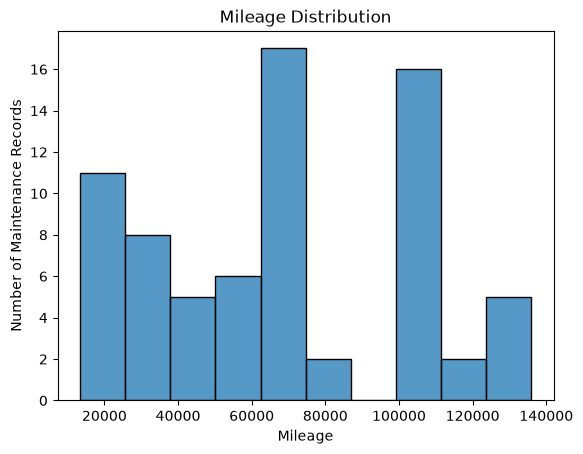

In [34]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.histplot(data=fact_df, x ="Mileage", bins=10)
plt.title("Mileage Distribution")
plt.xlabel("Mileage")
plt.ylabel("Number of Maintenance Records")
plt.show()

Q 5(b)
Created Bar chart comparing average maintenance cost

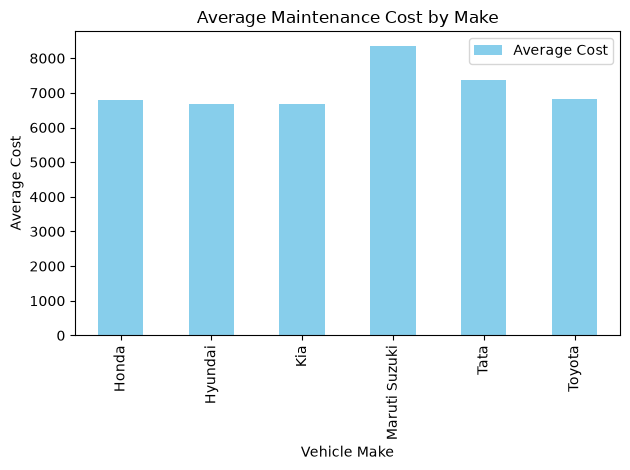

In [35]:
avg_cost = fact_df.groupby("Make")["Cost"].mean()

avg_cost.plot(kind="bar",
color="skyblue", label ="Average Cost")

plt.title("Average Maintenance Cost by Make")
plt.xlabel("Vehicle Make")
plt.ylabel("Average Cost")
plt.legend()
plt.tight_layout()
plt.show()

Q 5(C) 
Created a line chart to visualize monthly maintenance expenses.

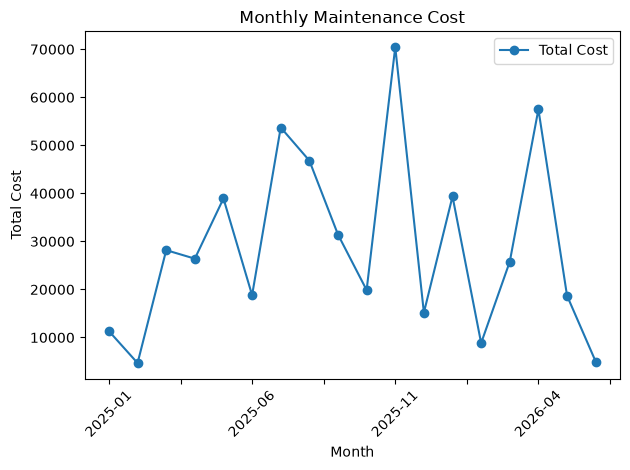

In [37]:
fact_df["StartTime"] = pd.to_datetime(fact_df["StartTime"], errors="coerce")

monthly = fact_df.groupby(
fact_df["StartTime"].dt.to_period("M"))["Cost"].sum()

monthly.index = monthly.index.astype(str)

monthly.plot(marker="o", label="Total Cost")
plt.title("Monthly Maintenance Cost")
plt.xlabel("Month")
plt.ylabel("Total Cost")
plt.xticks(rotation=45)
plt.legend()
plt.tight_layout()
plt.show()

Q 6(a)

Created a pie chart showing percentage of on time and delayed deliveries

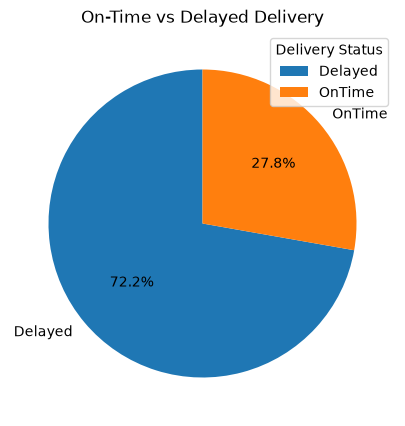

Delivery Percentages:
Delivery_Status
Delayed    72.222222
OnTime     27.777778
Name: proportion, dtype: float64


In [38]:
status = fact_df["Delivery_Status"].value_counts()

plt.figure(figsize=(7,5))
plt.pie(
    status,
    labels= status.index,
    autopct="%1.1f%%",
    startangle=90
)
plt.title("On-Time vs Delayed Delivery")
plt.legend(title="Delivery Status")
plt.show()

print("Delivery Percentages:")
print(fact_df["Delivery_Status"].value_counts(normalize=True) * 100)

Q 6(b)
CreatedBar chart for identifying the top 3 mechanics based on avg customers ratings

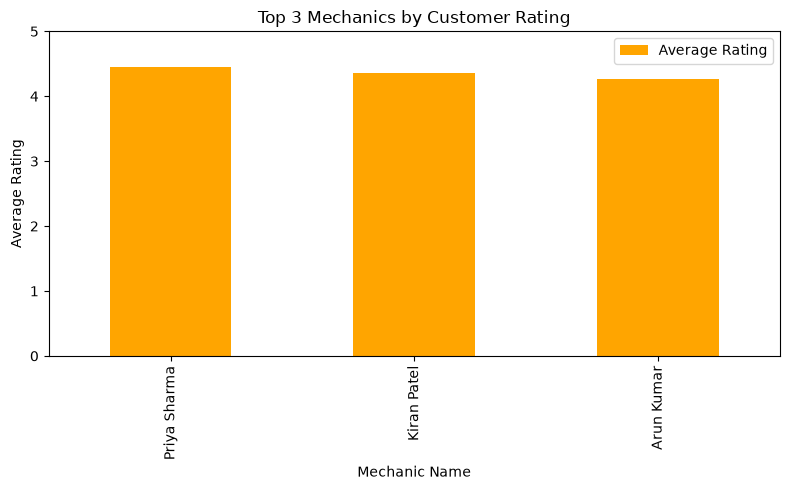

MechanicName
Priya Sharma    4.444444
Kiran Patel     4.363636
Arun Kumar      4.272727
Name: CustomerRating, dtype: float64


In [39]:
top3 = fact_df.groupby("MechanicName")["CustomerRating"].mean().nlargest(3)

plt.figure(figsize=(8,5))
top3.plot(kind="bar", color= "orange", label = "Average Rating")
plt.title("Top 3 Mechanics by Customer Rating")
plt.xlabel("Mechanic Name")
plt.ylabel("Average Rating")
plt.ylim(0,5)
plt.legend()
plt.tight_layout()
plt.show()

print(top3)

Q 6(c)
Created a bar chart for identifying the vehicle model with highest no of maintenance records

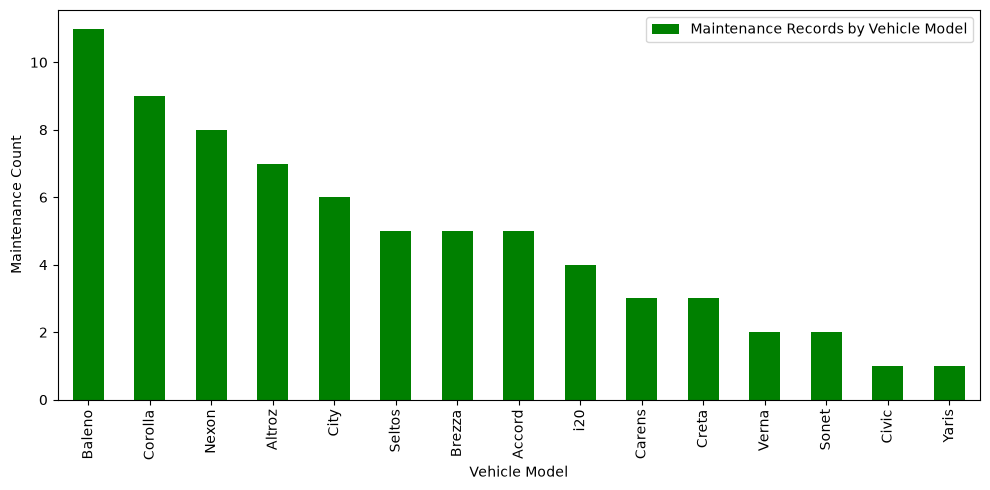

Most Maintained Model: Baleno
Number of Records: 11


In [41]:
models = fact_df["Model"].value_counts()

plt.figure(figsize=(10,5))
models.plot(kind="bar", color="green", label="Maintenance Records by Vehicle Model")
plt.xlabel("Vehicle Model")
plt.ylabel("Maintenance Count")
plt.legend()
plt.tight_layout()
plt.show()

print("Most Maintained Model:", models.idxmax())
print("Number of Records:", models.max())